In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse
import os
import sys
import pyabc
import seaborn as sns

import healpy as hp
from scipy.special import sph_harm
from scipy.stats import norm
import skyproj
from astropy.coordinates import SkyCoord, Angle
import astropy.units as u

sys.path.insert(0, '/work2/08811/aew492/frontera/lss-dipoles/code')
import tools
import dipole
import multipoles
import generate_mocks as gm
from abc_for_qso import get_catalog_info
from abc_fake_data import generate_fake_data

In [2]:
def get_abc_results_free_dipole(fn, xticks=None, title=None, plot=True):

    res = np.load(fn, allow_pickle=True).item()
    history = res['history']
    prior = res['prior']
    posterior = res['posterior']
    selfunc = res['selfunc']
    expected_dipamp = res['expected_dipole_amp']
    print(f"expected dipole_amp = {expected_dipamp}")

    # quantiles
    df, w = posterior
    par_ids = [x for x in prior.keys()]
    q = np.array([
        tools.quantile(df[par_id], [0.16, 0.5, 0.84], weights=w) for par_id in par_ids
    ])
    # get the inferred dipole from the median posterior
    
    # if the parameters are (x,y,z):
    if 'dipole_x' in par_ids:
        # then the median posterior are the inferred dipole (x,y,z) components
        inferred_dipole_comps = q[:,1]
        dipamps = np.linalg.norm(df, axis=1)
        expected_values = tools.dipole_dir_to_comps(dipole.cmb_dipole()[1]) * expected_dipamp
    # else if the parameters are (rho, costheta, phi)
    elif 'rho' in par_ids:
        inferred_dipole_comps = tools.rho_costheta_phi_to_xyz(*q[:,1])
        dipamps = df['rho']
        expected_dir = dipole.cmb_dipole()[1].icrs
        # get (theta, phi) in (RA, Dec)!
        theta, phi = tools.lonlat_to_thetaphi(expected_dir.ra, expected_dir.dec)
        expected_values = np.array([expected_dipamp, np.cos(theta.rad), phi.rad])
    else:
        raise ValueError("unrecognized par_ids")
    print("inferred dipole comps: ", inferred_dipole_comps)
    dipamp, dipdir = dipole.get_dipole(inferred_dipole_comps)
    
    print(f"inferred dipole has amplitude {dipamp:.5f} towards (l, b) = ({dipdir.galactic.l.deg:.2f}, " + \
          f"{dipdir.galactic.b.deg:.2f}) deg")

    # proper way to get z score?? how to get uncertainty in inferred dipole amplitude from the uncertainties
    #   in the three individual components? (my lack of error propagation skills haunting me once again..)
    q_amp = tools.weighted_quantile(dipamps, w, [0.16, 0.5, 0.84])
    sigma = pyabc.weighted_statistics.weighted_std(dipamps, w)
    # z score
    z = (expected_dipamp - q_amp[1]) / sigma
    print(f"z score = {z:.4f}")

    # plot (copied and adjusted from the pyabc.visualization source code)
    if plot:

        fig, axs = plt.subplots(len(par_ids), len(par_ids), figsize=(9,8), tight_layout=True)
        
        # color things
        cmap = mpl.colormaps['Blues']
        # get one of the colors for the 1D and scatter plots
        c = cmap(0.7)
        
        for i, par_id in enumerate(par_ids):
        
            # diagonal
            ax = axs[i, i]
            ax.axvline(q[i,1], c=c, alpha=0.4, ls='-', label='Median')
            ax.axvspan(q[i,0], q[i,2], color=c, alpha=0.05)
            x, pdf = tools.get_kde_1d(list(posterior), prior, par_id, numx=500)
            ax.plot(x, pdf, c=c, alpha=0.9, lw=2)
            ax.set_ylim(0., None)
            ax.grid(alpha=0.5, lw=0.5)
            label = 'Expected' if i == 0 else ''
            ax.axvline(expected_values[i], c='crimson', alpha=0.7, lw=2, label=label)
            if i == 0:
                ax.legend()
        
            axs[i,0].set_ylabel(par_id)
            axs[len(par_ids)-1,i].set_xlabel(par_id)
        
            for j in range(0, i):
        
                # lower
                ax = axs[i, j]
                x, y, pdf = tools.get_kde_2d(list(posterior), prior, par_ids[j], par_id)
                mesh = ax.pcolormesh(x, y, pdf, shading='auto', cmap=cmap)
        
                # upper
                ax = axs[j, i]
                tools.scatter(list(posterior), prior, par_id, par_ids[j], ax, color=c, alpha=0.3, marker='.', s=3)
                ax.grid(alpha=0.5, lw=0.5)
                
        # update all font sizes in the axes
        for ax in axs.flatten():
            for text in ax.findobj(match=plt.Text):
                text.set_fontsize(12)
                
        if title is not None:
            fig.suptitle(title)

        return q, res, dipamp, dipdir, expected_values, axs

    else:
        return q, res, dipamp, dipdir, expected_values

In [3]:
def convert_posterior_levels(pdf):
    pdf_flat = pdf.ravel()
    idx = np.argsort(pdf_flat)[::-1]
    pdf_sorted = pdf_flat[idx]
    
    cdf = np.cumsum(pdf_sorted)
    cdf /= cdf[-1]  # normalize total probability to 1
    
    levels = []
    for p in [0.95, 0.68]:
        levels.append(pdf_sorted[np.searchsorted(cdf, p)])
    return levels

In [4]:
def standard_dipole(qmap_masked, selfunc, expected_dipole_amp=None):

    # mask
    qmap_masked[np.isnan(qmap_masked)] = 0.  # need to turn NaNs into zeros in order to downgrade the resolution properly
    # correct by selfunc
    qmap_corr = qmap_masked / selfunc
    # overdensity map
    odmap = qmap_corr / np.nanmean(qmap_corr) - 1
    # inverse variance
    odmap_Cinv = selfunc * np.nanmean(qmap_corr)

    # measure dipole
    dipcomps, stderr = dipole.measure_overdensity_dipole_Lambda(odmap, 0., Cinv=odmap_Cinv, return_err=True)
    dipamp, dipdir = dipole.get_dipole(dipcomps)
    
    # propagate error
    dipamp_std, theta_std, phi_std = tools.dipamp_err(dipcomps, stderr)
    
    res = {
        'dipamp' : dipamp,
        'dipamp_std' : dipamp_std,
        'dipdir' : dipdir,
        'dipdir_std' : theta_std
    }
    
    if expected_dipole_amp is not None:
        res['relamp'] = dipamp / expected_dipole_amp
        res['relstd'] = dipamp_std / expected_dipole_amp
        res['zscore'] = (expected_dipole_amp - dipamp) / dipamp_std
    
    return res

In [5]:
blim = 30
nside = 2
nside_hi = 64
resdir = '/work2/08811/aew492/frontera/lss-dipoles_results'

# expected dipole direction
cmb_dipdir = dipole.cmb_dipole()[1]

### load fake data: ideal Quaia G20.0: kinematic dipole + shot noise (no excess power)

In [6]:
# ideal Quaia G20.0: kinematic dipole + shot noise (no excess power)
sample_name = 'quaia_G20.0'
cat_info = get_catalog_info(sample_name)
base_rate = cat_info['base_rate']
selfunc_str = cat_info['selfunc_str']
itrial = 0

#### ABC results

In [7]:
q, res, dipamp_abc, dipdir_abc, expected_vals = get_abc_results_free_dipole(os.path.join(resdir,
                            f'ABC/fake_data/{selfunc_str}_base-rate-{base_rate:.4f}_dipamp-1.0x_excess-zero',
                                                            f'trials/trial{itrial}',
                                            f'free_dipole_nside{nside}_500mocks_15iters_flat-prior-spherical',
                                                                 f'results.npy'), plot=False)
fake_data_dict = res['fake_data_dict']

# get the weighed quantiles of the relative amplitude ?!
df, w = res['posterior']
dipamps = df['rho']
q_amp = tools.weighted_quantile(dipamps, w, [0.16, 0.5, 0.84])
rel_q_amp = q_amp / cat_info['expected_dipole_amp']

# print the quantiles
print(f"measured dipole amp. = {q_amp[1]:.4f} +{q_amp[2]-q_amp[1]:.4f} -{q_amp[1]-q_amp[0]:.4f}")
# and the relative amplitude
print(f"relative dipole amp. = {rel_q_amp[1]:.3f} +{rel_q_amp[2]-rel_q_amp[1]:.3f} -{rel_q_amp[1]-rel_q_amp[0]:.3f}")
# and the b err
berr = tools.dipdir_b_err(df, w)
print(f"latitude error = {berr:.1f}deg")

expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00655163 -0.00018297 -0.00265234]
inferred dipole has amplitude 0.00707 towards (l, b) = (289.34, 39.65) deg
z score = -0.4826
measured dipole amp. = 0.0071 +0.0045 -0.0037
relative dipole amp. = 1.359 +0.874 -0.710
latitude error = 23.5deg


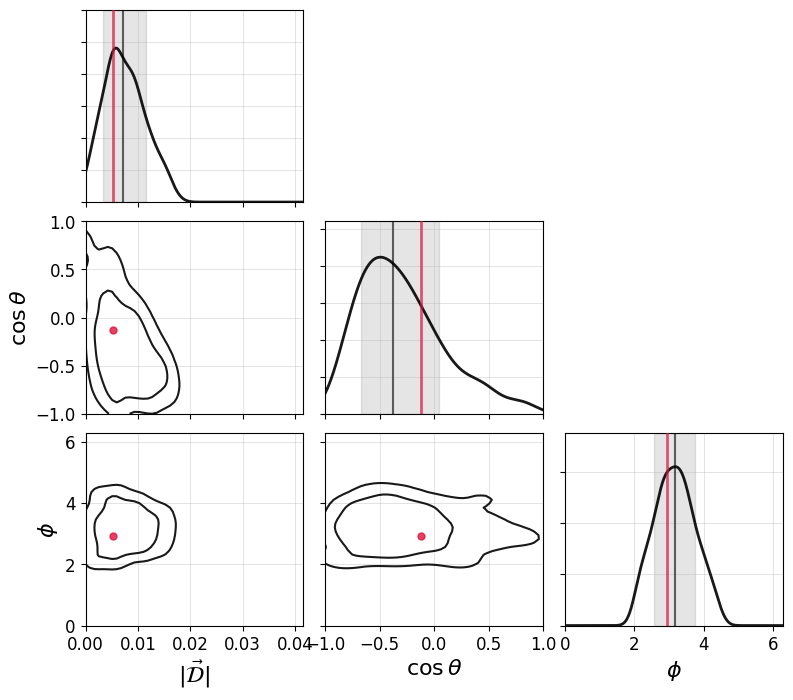

In [8]:
# plot component posteriors:
fig, axs = plt.subplots(3, 3, figsize=(9,8), gridspec_kw = {'hspace' : 0.1, 'wspace' : 0.1})

# alphas for the contour plot
alphas = [0.3, 0.9]
# y axis limits for the diagonals
ylims = [120, 1.3, 0.75]
# axis names
par_ids = [x for x in res['prior'].keys()]
par_labels = [r'$|\vec{\mathcal{D}}|$', r'$\cos\theta$', r'$\phi$']
        
# color and linestyle things
c = 'k'
ls = '-'
zorder = 20

posterior = res['posterior']
prior = res['prior']

for i, (par_id, par_label, ylim) in enumerate(zip(par_ids, par_labels, ylims)):

    # diagonal
    ax = axs[i, i]
    label = 'Injected' if i==0 else ''
    ax.axvline(expected_vals[i], c='crimson', alpha=0.7, lw=2, label=label, zorder=30)
    ax.axvline(q[i,1], c=c, alpha=0.6, ls='-')
    ax.axvspan(q[i,0], q[i,2], color=c, alpha=0.1, zorder=0)
    x, pdf = tools.get_kde_1d(list(posterior), prior, par_id, numx=1000)
    ax.plot(x, pdf, c=c, alpha=0.9, lw=2, ls=ls, zorder=zorder)
    ax.set_ylim(0., ylim)
    ax.set_xlim(prior[par_id].args[0], prior[par_id].args[0] + prior[par_id].args[1])
    ax.grid(alpha=0.5, lw=0.5)
    if i != 2:
        ax.set_xticklabels([])
    ax.set_yticklabels([])

    if i != 0:
        axs[i,0].set_ylabel(par_label, fontsize=16)
    axs[len(par_ids)-1,i].set_xlabel(par_label, fontsize=16)

    for j in range(0, i):

        # lower
        ax = axs[i, j]
        x, y, pdf = tools.get_kde_2d(list(posterior), prior, par_ids[j], par_id)
        levels = convert_posterior_levels(pdf)
        for lvl, a in zip(levels, alphas):
            ax.contour(x, y, pdf, levels=[lvl], colors=c, alpha=0.9, linestyles=ls, zorder=zorder)
        ax.plot(expected_vals[j], expected_vals[i], c='crimson', marker='.', alpha=0.8, ms=10, zorder=30)
        ax.grid(alpha=0.5, lw=0.5)
        ax.set_xlim(prior[par_ids[j]].args[0], prior[par_ids[j]].args[0] + prior[par_ids[j]].args[1])
        ax.set_ylim(prior[par_id].args[0], prior[par_id].args[0] + prior[par_id].args[1])
        if i == 2 and j == 1:
            ax.set_yticklabels([])
        if i == 1:
            ax.set_xticklabels([])

        # upper
        axs[j,i].set_axis_off()
                
# update all font sizes in the axes
for ax in axs.flatten():
    for text in ax.findobj(match=plt.Text):
        text.set_fontsize(12)

for ax in axs.flatten():
    for text in ax.findobj(match=lambda a: a in (ax.xaxis.label, ax.yaxis.label)):
        text.set_fontsize(16)
# fig.legend(fontsize=12, bbox_to_anchor=(0.55, 0.75))

#### plot data

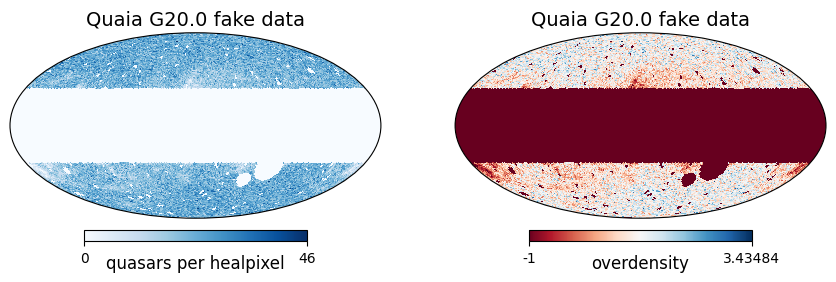

In [9]:
datamap = fake_data_dict['data']['data']
odmap = fake_data_dict['odmap']
hp.projview(datamap, coord=['C','G'], cmap='Blues', sub=(1,2,1), unit='quasars per healpixel', title='Quaia G20.0 fake data')
hp.projview(odmap, coord=['C','G'], cmap='RdBu', sub=(1,2,2), unit='overdensity', title='Quaia G20.0 fake data')

#### least-squares fit

In [10]:
lstsq_res = standard_dipole(datamap, fake_data_dict['selfunc'], fake_data_dict['input_dipole_amp'])

/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc


In [11]:
lstsq_res

{'dipamp': 0.007911595774630322,
 'dipamp_std': 0.002442097542294012,
 'dipdir': <SkyCoord (ICRS): (ra, dec) in deg
     (184.75097096, -31.01880964)>,
 'dipdir_std': 0.35037770647636746,
 'relamp': 1.5214607258904467,
 'relstd': 0.4696341427488485,
 'zscore': -1.110355228515219}

#### compare both methods

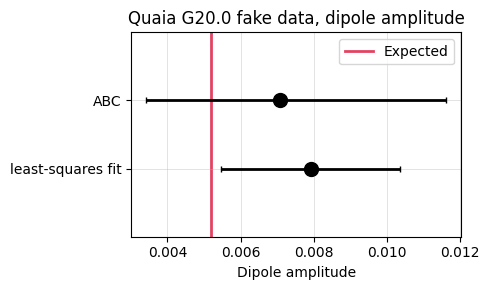

In [12]:
fig, ax = plt.subplots(figsize=(5,3), tight_layout=True)
ax.errorbar(lstsq_res['dipamp'], 1, marker='o', xerr=lstsq_res['dipamp_std'],
            capsize=2, c='k', ms=10, lw=2)
q_err = np.array([[q[0,1] - q[0,0], q[0,2] - q[0,1]]]).T
ax.errorbar(q[0,1], 2, xerr=q_err, marker='o', capsize=2, c='k', ms=10, lw=2)
ax.axvline(cat_info['expected_dipole_amp'], c='crimson', lw=2, alpha=0.8, zorder=0,
          label='Expected')
ax.grid(alpha=0.5, lw=0.5)
ax.set_xlabel(r'Dipole amplitude')
ax.set_yticks([1., 2.,], labels=['least-squares fit', 'ABC'])
ax.set_ylim(0., 3.)
ax.set_title('Quaia G20.0 fake data, dipole amplitude')
ax.legend()

/work2/08811/aew492/frontera/venv/dipole/lib/python3.9/site-packages/skyproj/_skyproj.py:628: FutureWarning: skyproj.scatter() has been deprecated and will be removed in v2.5. Please access via skyproj.ax.scatter()
  warnings.warn(


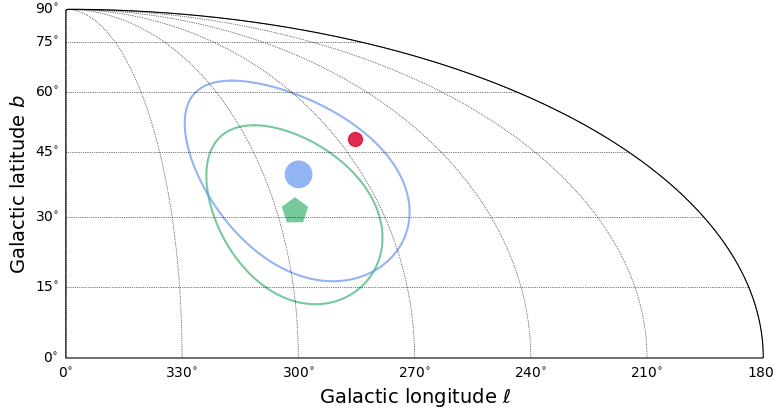

In [20]:
# direction
fig, ax = plt.subplots(figsize=(9,6))
sp = skyproj.MollweideSkyproj(ax=ax, extent=[180, 360, 0, 90])
sp.ax.tick_params(fontsize=16)

# labels and gridlines
sp.ax.set_xlabel(r'Galactic longitude $\ell$', fontsize=14)
sp.ax.set_ylabel(r'Galactic latitude $b$', fontsize=14)
sp.ax.tick_params(fontsize=12)
sp.ax.gridlines.set_alpha(0.4)

# least-squares fit
dipdir = lstsq_res['dipdir']
l, b = dipdir.galactic.l.deg, dipdir.galactic.b.deg
dir_err = lstsq_res['dipdir_std']
sp.scatter(l, b, color='mediumseagreen', edgecolor='None', ls='-',
           s=400, alpha=0.7, zorder=10, linewidths=2, marker='p')
sp.ax.ellipse(l, b, dir_err * 180 / np.pi, dir_err * 180 / np.pi, 0, color='mediumseagreen', alpha=0.7, ls='-')

# ABC
l, b = dipdir_abc.galactic.l.deg, dipdir_abc.galactic.b.deg
sp.scatter(l, b, color='cornflowerblue', edgecolor='None', ls='-',
           s=400, alpha=0.7, zorder=10, linewidths=2, marker='o')
sp.ax.ellipse(l, b, berr, berr, 0, color='cornflowerblue', alpha=0.7, ls='-')

sp.scatter(cmb_dipdir.galactic.l.deg, cmb_dipdir.galactic.b.deg, color='crimson', 
        label=f'Expected (CMB)', s=400, marker='.', alpha=0.9)

### several mocks. is the least-squares fit result consistently high?

In [21]:
nmocks = 1000
data_dipole_amp = cat_info['expected_dipole_amp']
base_rate = cat_info['base_rate']
log_excess = -30

ress = []

for i in tqdm(range(nmocks)):
    fake_data_dict = generate_fake_data(sample_name, data_dipole_amp, log_excess, base_rate,
                                        poisson=True, selfunc=cat_info['selfunc_str'])
    datamap = fake_data_dict['data']['data']
    lstsq_res = standard_dipole(datamap, fake_data_dict['selfunc'], fake_data_dict['input_dipole_amp'])
    ress.append(lstsq_res)

  0%|          | 0/1000 [00:00<?, ?it/s]/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
100%|██████████| 1000/1000 [00:46<00:00, 21.68it/s]


average dipole amp = 0.00669


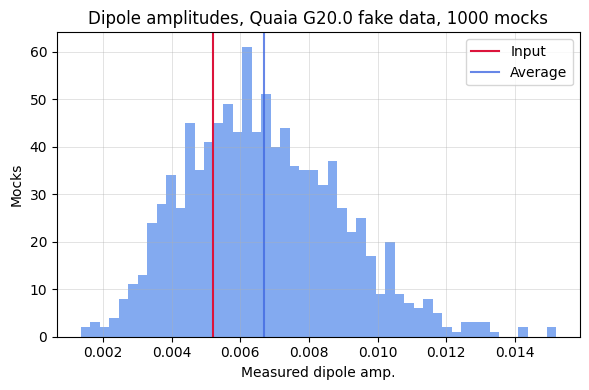

In [22]:
dipamps = np.array([
    x['dipamp'] for x in ress
])
avg_dipamp = np.mean(dipamps)
print(f"average dipole amp = {avg_dipamp:.5f}")
fig, ax = plt.subplots(figsize=(6,4), tight_layout=True)
_, _, _ = ax.hist(dipamps, color='cornflowerblue', alpha=0.8, bins=50)
ax.axvline(cat_info['expected_dipole_amp'], c='crimson', label='Input')
ax.axvline(avg_dipamp, c='royalblue', alpha=0.8, label='Average')
ax.grid(alpha=0.5, lw=0.5)
ax.set_xlabel(r'Measured dipole amp.')
ax.set_ylabel(r'Mocks')
ax.set_title(f'Dipole amplitudes, Quaia G20.0 fake data, {nmocks} mocks')
ax.legend()

I suspect the positive bias is mainly from the Cartesian parameterization---since the dipole amplitude is a sum of squares. If we used ABC to infer the dipole amplitudes with $(\mathcal D,\cos\theta,\phi)$ parameterization, I suspect this bias would disappear

In [23]:
# what's the average uncertainty?
dipamp_stds = np.array([
    x['dipamp_std'] for x in ress
])
print(f"min dipole amp std = {np.min(dipamp_stds):.6f}")
print(f"max dipole amp std = {np.max(dipamp_stds):.6f}")
print(f"avg dipole amp std = {np.mean(dipamp_stds):.6f}")

min dipole amp std = 0.002226
max dipole amp std = 0.003069
avg dipole amp std = 0.002547


### with ABC

In [30]:
ntrials = 24
qs = []
dipamps_abc = []
dipdirs_abc = []
lstsq_ress = []
for itrial in range(ntrials):
    q, res, dipamp_abc, dipdir_abc, expected_vals = get_abc_results_free_dipole(os.path.join('../results',
                            f'ABC/fake_data/{selfunc_str}_base-rate-{base_rate:.4f}_dipamp-1.0x_excess-zero',
                                                            f'trials/trial{itrial}',
                                            f'free_dipole_nside{nside}_500mocks_15iters_flat-prior-spherical',
                                                                 f'results.npy'), plot=False)
    qs.append(q)
    dipamps_abc.append(dipamp_abc)
    dipdirs_abc.append(dipdir_abc)
    # also use the least-squares fit to measure
    datamap = res['fake_data_dict']['data']['data']
    lstsq_res = standard_dipole(datamap, fake_data_dict['selfunc'], fake_data_dict['input_dipole_amp'])
    lstsq_ress.append(lstsq_res)

expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00288065  0.00120139  0.00031678]
inferred dipole has amplitude 0.00314 towards (l, b) = (238.75, 50.08) deg
z score = 0.8467
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00412372  0.00323019  0.00156386]
inferred dipole has amplitude 0.00547 towards (l, b) = (214.53, 41.91) deg
z score = -0.0832
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00498648  0.00017554  0.00258065]
inferred dipole has amplitude 0.00562 towards (l, b) = (208.56, 76.78) deg
z score = -0.1187
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00567039  0.00016793  0.00334691]
inferred dipole has amplitude 0.00659 towards (l, b) = (194.51, 76.81) deg
z score = -0.5262
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00253182  0.00063507  0.00146528]
inferred dipole has amplitude 0.00299 towards (l, b) = (201.32, 66.21) deg
z score = 0.7932
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00854583  0.00019758  0.0

/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc


z score = 0.3588
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.0043597   0.00195288 -0.00185951]
inferred dipole has amplitude 0.00513 towards (l, b) = (262.68, 29.81) deg
z score = 0.0196
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00286468 -0.00434928  0.00230832]
inferred dipole has amplitude 0.00570 towards (l, b) = (38.32, 50.56) deg
z score = -0.1570
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00326332  0.00393269 -0.00117879]
inferred dipole has amplitude 0.00524 towards (l, b) = (237.66, 16.79) deg
z score = -0.0284
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00365075 -0.00069592  0.00274778]
inferred dipole has amplitude 0.00462 towards (l, b) = (133.04, 80.49) deg
z score = 0.1915
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00543842  0.00517084  0.0031931 ]
inferred dipole has amplitude 0.00816 towards (l, b) = (204.30, 39.16) deg
z score = -0.8980
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00551664 

/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc


expected dipole_amp = 0.0052
inferred dipole comps:  [-0.0051245  -0.00063999 -0.00141253]
inferred dipole has amplitude 0.00535 towards (l, b) = (294.77, 47.21) deg
z score = -0.0428
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00332194 -0.00217105  0.00085667]
inferred dipole has amplitude 0.00406 towards (l, b) = (358.77, 65.80) deg
z score = 0.4654
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00335417 -0.00037125  0.0025273 ]
inferred dipole has amplitude 0.00422 towards (l, b) = (151.02, 78.83) deg
z score = 0.3187
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00448981 -0.00084167 -0.00144365]
inferred dipole has amplitude 0.00479 towards (l, b) = (299.89, 45.28) deg
z score = 0.1168
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00396139 -0.00074954  0.00026055]
inferred dipole has amplitude 0.00404 towards (l, b) = (297.56, 66.48) deg
z score = 0.4000
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00829002  0.00035115  0.001

/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc


expected dipole_amp = 0.0052
inferred dipole comps:  [-0.01026602  0.00373684  0.00072212]
inferred dipole has amplitude 0.01095 towards (l, b) = (243.79, 50.90) deg
z score = -1.8579
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00620664  0.00156656 -0.00052576]
inferred dipole has amplitude 0.00642 towards (l, b) = (259.46, 48.84) deg
z score = -0.3612
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00671496 -0.00196769 -0.00200234]
inferred dipole has amplitude 0.00728 towards (l, b) = (307.81, 46.77) deg
z score = -0.5809
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00271723 -0.00042405  0.00148079]
inferred dipole has amplitude 0.00312 towards (l, b) = (193.66, 86.28) deg
z score = 0.8005
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.0036459  -0.00024147  0.00070168]
inferred dipole has amplitude 0.00372 towards (l, b) = (273.50, 71.64) deg
z score = 0.3898


/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc


In [34]:
dipamps_lstsq = np.array([
    x['dipamp'] for x in lstsq_ress
])

average dipole amp, ABC = 0.00557
average dipole amp, lstsq = 0.00647


Text(0.5, 0.98, 'Dipole amplitudes, Quaia G20.0 fake data, 24 mocks')

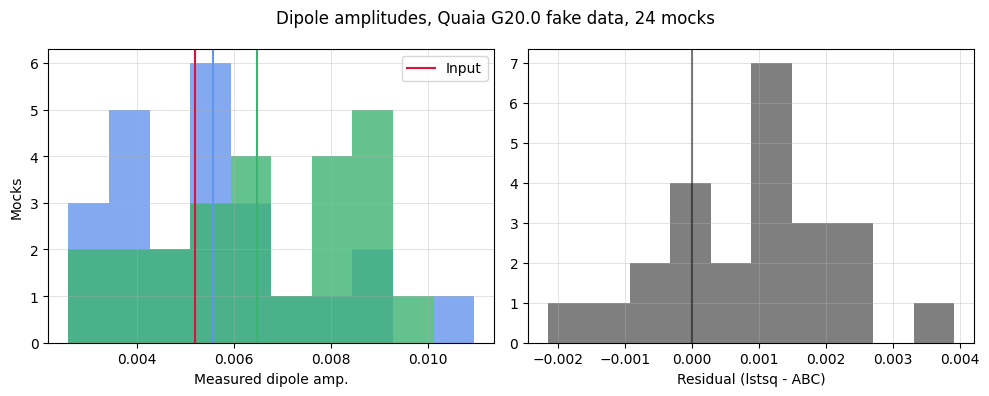

In [43]:
cs = ['cornflowerblue', 'mediumseagreen']
labels = ['ABC', 'lstsq']
fig, axs = plt.subplots(1, 2, figsize=(10,4), tight_layout=True)
bins = np.linspace(np.amin([dipamps_abc, dipamps_lstsq]), np.amax([dipamps_abc, dipamps_lstsq]), 11)
for (dipamps_, c, label) in zip([dipamps_abc, dipamps_lstsq], cs, labels):
    _, _, _ = axs[0].hist(dipamps_, color=c, bins=bins, alpha=0.8)
    avg_dipamp = np.mean(dipamps_)
    print(f"average dipole amp, {label} = {avg_dipamp:.5f}")
    axs[0].axvline(avg_dipamp, c=c, alpha=1.)
_, _, _ = axs[1].hist(dipamps_lstsq - dipamps_abc, color='k', alpha=0.5, bins=10)
axs[0].axvline(cat_info['expected_dipole_amp'], c='crimson', label='Input')
axs[1].axvline(c='k', alpha=0.5)
for ax in axs:
    ax.grid(alpha=0.5, lw=0.5)
axs[0].set_ylabel(r'Mocks')
axs[0].set_xlabel(r'Measured dipole amp.')
axs[1].set_xlabel(r'Residual (lstsq - ABC)')
axs[0].legend()
fig.suptitle(f'Dipole amplitudes, Quaia G20.0 fake data, {ntrials} mocks')

In [45]:
dipdirs_lstsq = np.array([
    x['dipdir'] for x in lstsq_ress
])

/work2/08811/aew492/frontera/venv/dipole/lib/python3.9/site-packages/skyproj/_skyproj.py:628: FutureWarning: skyproj.scatter() has been deprecated and will be removed in v2.5. Please access via skyproj.ax.scatter()
  warnings.warn(


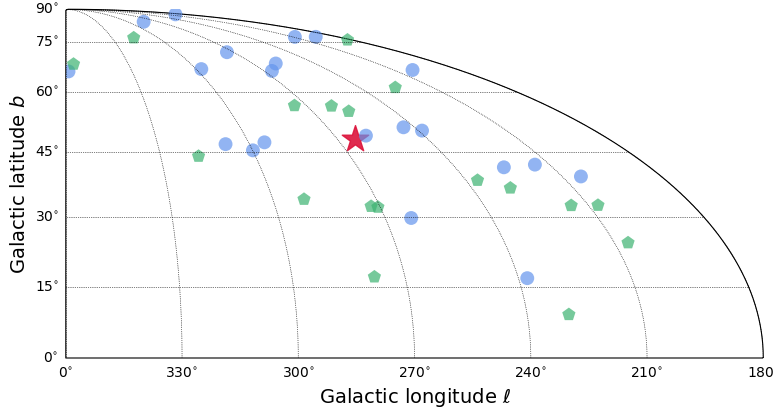

In [47]:
# direction
fig, ax = plt.subplots(figsize=(9,6))
sp = skyproj.MollweideSkyproj(ax=ax, extent=[180, 360, 0, 90])
sp.ax.tick_params(fontsize=16)

# labels and gridlines
sp.ax.set_xlabel(r'Galactic longitude $\ell$', fontsize=14)
sp.ax.set_ylabel(r'Galactic latitude $b$', fontsize=14)
sp.ax.tick_params(fontsize=12)
sp.ax.gridlines.set_alpha(0.4)

for dipdir in dipdirs_abc:
    l, b = dipdir.galactic.l.deg, dipdir.galactic.b.deg
    sp.scatter(l, b, color='cornflowerblue', edgecolor='None', ls='-',
               s=100, alpha=0.7, zorder=10, linewidths=2, marker='o')
    # sp.ax.ellipse(l, b, berr, berr, 0, color='cornflowerblue', alpha=0.7, ls='-')
    
for dipdir in dipdirs_lstsq:
    l, b = dipdir.galactic.l.deg, dipdir.galactic.b.deg
    sp.scatter(l, b, color='mediumseagreen', edgecolor='None', ls='-',
               s=100, alpha=0.7, zorder=10, linewidths=2, marker='p')

sp.scatter(cmb_dipdir.galactic.l.deg, cmb_dipdir.galactic.b.deg, color='crimson', 
        label=f'Expected (CMB)', s=400, marker='*', alpha=0.9)